<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/02_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, matplotlib.pyplot as plt

df = pd.read_parquet('/content/drive/MyDrive/proyecto_multimodal/data/mmimdb_meta.parquet')
GENEROS = list(df.columns[4:])
tr = df['particion'] == 'train'
print(df.shape, "|", len(GENEROS), "géneros")

# Estilo sobrio para todos los gráficos
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
AZUL = '#2563eb'

Mounted at /content/drive
(25959, 27) | 23 géneros


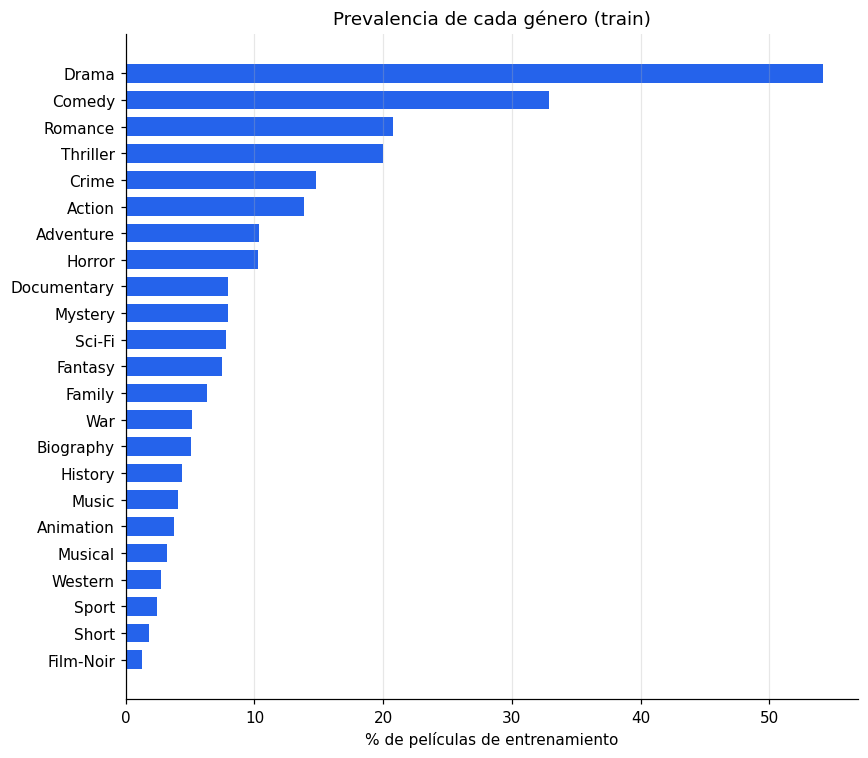

Drama          54.2
Comedy         32.8
Romance        20.7
Thriller       20.0
Crime          14.7
Action         13.9
Adventure      10.4
Horror         10.3
Documentary     7.9
Mystery         7.9
Sci-Fi          7.8
Fantasy         7.5
Family          6.3
War             5.2
Biography       5.1
History         4.4
Music           4.1
Animation       3.8
Musical         3.2
Western         2.7
Sport           2.4
Short           1.8
Film-Noir       1.3

Razón de desbalance Drama / Film-Noir: 42 veces
Mayor diferencia de prevalencia entre train/dev/test: 1.06 puntos porcentuales


In [2]:
prev = df.loc[tr, GENEROS].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(prev.index, prev.values * 100, color=AZUL, height=0.7)
ax.set_xlabel('% de películas de entrenamiento')
ax.set_title('Prevalencia de cada género (train)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

print((prev.sort_values(ascending=False) * 100).round(1).to_string())
print(f"\nRazón de desbalance Drama / Film-Noir: {prev.max() / prev.min():.0f} veces")

p = df.groupby('particion')[GENEROS].mean().T
print("Mayor diferencia de prevalencia entre train/dev/test:",
      round(float((p.max(axis=1) - p.min(axis=1)).max() * 100), 2), "puntos porcentuales")

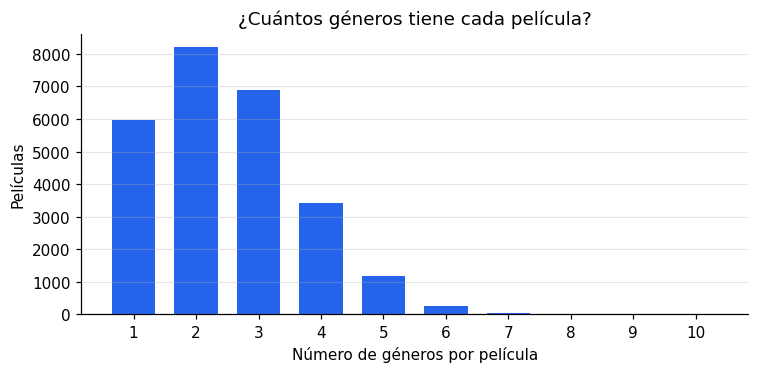

1     5965
2     8211
3     6894
4     3404
5     1172
6      255
7       47
8        6
9        3
10       2

Películas con un solo género: 23.0%


In [3]:
k = df[GENEROS].sum(axis=1)
cuenta = k.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(cuenta.index, cuenta.values, color=AZUL, width=0.7)
ax.set_xticks(cuenta.index)
ax.set_xlabel('Número de géneros por película'); ax.set_ylabel('Películas')
ax.set_title('¿Cuántos géneros tiene cada película?')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

print(cuenta.to_string())
print(f"\nPelículas con un solo género: {(k == 1).mean():.1%}")

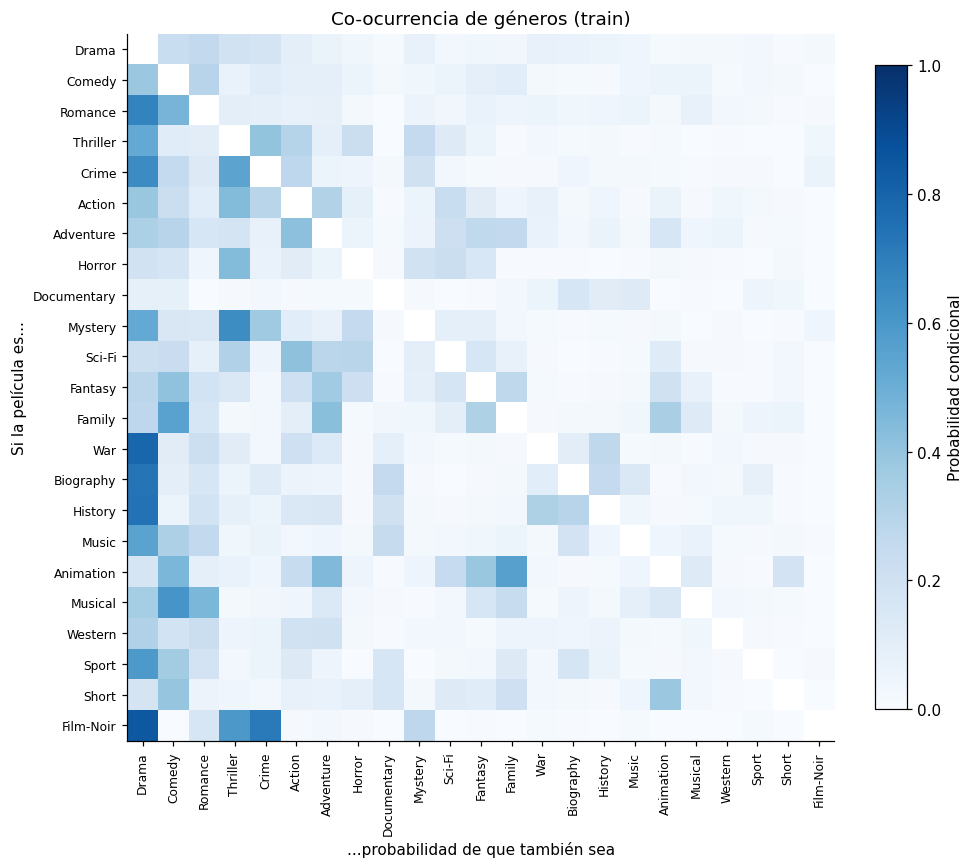

Pares más asociados (lift = cuántas veces más que por azar):
  Animation    + Short        lift=10.1  (107 películas)
  Family       + Animation    lift= 8.9  (329 películas)
  War          + History      lift= 6.2  (218 películas)
  Biography    + History      lift= 5.8  (200 películas)
  Fantasy      + Animation    lift= 5.2  (228 películas)
  Crime        + Film-Noir    lift= 4.8  (144 películas)
  Fantasy      + Family       lift= 4.3  (315 películas)
  Adventure    + Animation    lift= 4.3  (261 películas)
  Adventure    + Family       lift= 4.1  (416 películas)
  Family       + Musical      lift= 3.8  (121 películas)


In [4]:
orden = list(prev.sort_values(ascending=False).index)
Yt = df.loc[tr, orden].values.astype(float)
co = Yt.T @ Yt                                  # películas que comparten cada par
cond = co / np.diag(co)[:, None]                # P(género columna | género fila)
np.fill_diagonal(cond, np.nan)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cond, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(23), orden, rotation=90, fontsize=8)
ax.set_yticks(range(23), orden, fontsize=8)
ax.set_ylabel('Si la película es...'); ax.set_xlabel('...probabilidad de que también sea')
ax.set_title('Co-ocurrencia de géneros (train)')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label='Probabilidad condicional')
plt.tight_layout(); plt.show()

# Pares que aparecen juntos mucho más de lo esperado por azar
n = len(Yt); pg = Yt.mean(axis=0)
lift = (co / n) / np.outer(pg, pg)
pares = [(orden[i], orden[j], lift[i, j], int(co[i, j]))
         for i in range(23) for j in range(i + 1, 23) if co[i, j] >= 30]
pares.sort(key=lambda x: -x[2])
print("Pares más asociados (lift = cuántas veces más que por azar):")
for a, b, l, c in pares[:10]:
    print(f"  {a:12s} + {b:12s} lift={l:4.1f}  ({c} películas)")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (208 > 77). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (556 > 512). Running this sequence through the model will result in indexing errors


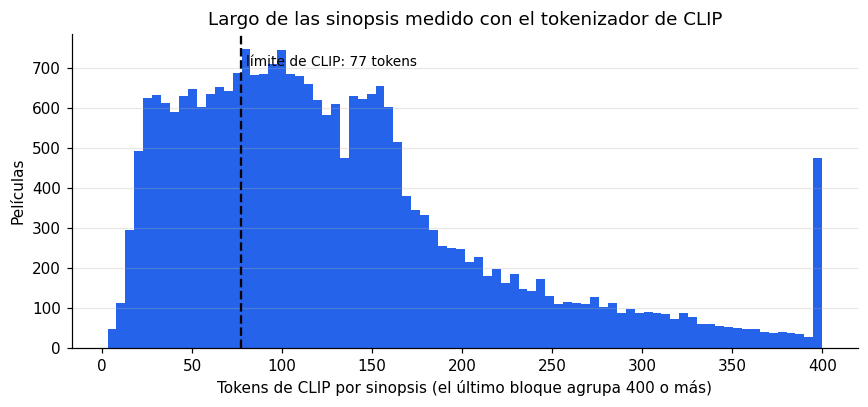

CLIP: mediana=114 tokens | percentil 95=317
CLIP: superan 77 tokens: 69.6%
Fragmentos de 77 tokens necesarios por película:
1          7903
2          9896
3          4771
4          1852
5           932
6 o más     605

DistilBERT: superan 512 tokens: 0.5%


In [5]:
!pip install -q transformers
from transformers import AutoTokenizer

tok_clip = AutoTokenizer.from_pretrained('openai/clip-vit-base-patch32')
tok_bert = AutoTokenizer.from_pretrained('distilbert-base-uncased')

textos = df['sinopsis'].tolist()
n_clip = np.array([len(x) for x in tok_clip(textos, truncation=False)['input_ids']])
n_bert = np.array([len(x) for x in tok_bert(textos, truncation=False)['input_ids']])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(np.minimum(n_clip, 400), bins=80, color=AZUL)
ax.axvline(77, color='black', lw=1.5, ls='--')
ax.text(80, ax.get_ylim()[1] * 0.9, 'límite de CLIP: 77 tokens', fontsize=9)
ax.set_xlabel('Tokens de CLIP por sinopsis (el último bloque agrupa 400 o más)')
ax.set_ylabel('Películas')
ax.set_title('Largo de las sinopsis medido con el tokenizador de CLIP')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

frag = np.ceil((n_clip - 2) / 75).astype(int)   # 75 tokens útiles por fragmento + 2 especiales
print(f"CLIP: mediana={np.median(n_clip):.0f} tokens | percentil 95={np.percentile(n_clip, 95):.0f}")
print(f"CLIP: superan 77 tokens: {(n_clip > 77).mean():.1%}")
print("Fragmentos de 77 tokens necesarios por película:")
print(pd.Series(np.minimum(frag, 6)).value_counts().sort_index()
        .rename(index={6: '6 o más'}).to_string())
print(f"\nDistilBERT: superan 512 tokens: {(n_bert > 512).mean():.1%}")